In [1]:
!pip install pychomp2
!pip install CMGDB
!pip install git+https://github.com/marciogameiro/GP_MorseGraph.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 705.7/705.7 kB 14.9 MB/s eta 0:00:00
  Cloning https://github.com/marciogameiro/GP_MorseGraph.git to /tmp/pip-req-build-n7d_gsj5
  Running command git clone --filter=blob:none --quiet https://github.com/marciogameiro/GP_MorseGraph.git /tmp/pip-req-build-n7d_gsj5
  Resolved https://github.com/marciogameiro/GP_MorseGraph.git to commit ea83af9c4588b0bb0570cef9df5715019ae1bb46
  Preparing metadata (setup.py) ... done
  Created wheel for GPDynamics: filename=gpdynamics-0.0.1-py3-none-any.whl size=4939 sha256=7210ec748b1324ce32558c2eb1440326523ed37240c04b61179118b870e8cc21
  Stored in directory: /tmp/pip-ephem-wheel-cache-vx5e_y5n/wheels/83/42/82/60286a5bf272125c2d3796da1ab3315d8338d4129aaab515ff
Successfully built GPDynamics


In [2]:
import CMGDB
import GPDynamics as GPD

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
import matplotlib
import numpy as np
import math
import time

In [3]:
# Color list to plot Morse graph and Morse sets
clr_list = ['#0000ff77', '#fe010077', '#90d743', '#e8cb3288',
            '#0000ff77', '#fe010077', '#44015499', '#44398399', '#31688e99', '#fcad61',
            '#35b779', '#90d743', '#e8cb32', '#ffffb3', '#fccde5', '#ffed6f', '#0000ff77',
            '#fe010077', '#44015499', '#44398399', '#31688e99', '#fcad61', '#35b779',
            '#90d743', '#e8cb32', '#ffffb3', '#fccde5', '#ffed6f', '#0000ff77', '#fe010077',
            '#44015499', '#44398399', '#31688e99', '#fcad61', '#35b779', '#90d743', '#e8cb32',
            '#ffffb3', '#fccde5', '#ffed6f', '#0000ff77', '#fe010077', '#44015499', '#44398399',
            '#31688e99', '#fcad61', '#35b779', '#90d743', '#e8cb32', '#ffffb3', '#fccde5', '#ffed6f']

##Problem (P)

In [4]:
# Confidence level and Lipschitz bound in GP used to create the multivalued map for homological dynamics
# See Identifying Nonlinear Dynamics with High Confidence from Sparse Data for more details at:
# https://epubs.siam.org/doi/abs/10.1137/23M1560252  or  https://arxiv.org/abs/2206.13779

confidence_level = 0.95
L = 12

# Upper and lower bounds for the domain and the number of subdivisions for the 1d cell complex
lower_bounds = [-0.1]
upper_bounds = [4]
phase_subdiv = 10

# Generate data -- here we sample from the Ricker map rounding to 1 decimal place
def f(x):
    r = 2.3
    return [x[0] * math.exp(r-x[0])]

x=[0.2] # initial condition
y=f(x)
X=[x]
Y=[np.round(f(x), decimals=1)]

# iterate the map
for i in range(6):
  x=y
  y=f(x)
  X.append(np.round(x, decimals=1))
  Y.append(np.round(y, decimals=1))

X = np.array(X)
Y = np.array(Y)

print(f"X={X.T}")
print(f"Y={Y.T}")

X=[[0.2 1.6 3.2 1.3 3.5 1.  3.7]]
Y=[[1.6 3.2 1.3 3.5 1.  3.7 0.9]]


In [5]:
%%time
# Perform Gaussian Process regression
#K = 1.0 * RBF(length_scale=1.0, length_scale_bounds=(1e-1, 5.0))
K = 1.0 * RBF(length_scale=1.0, length_scale_bounds=(1e-1, 5.0)) + WhiteKernel(0.000015, noise_level_bounds=(1e-10, 2e-5))
# Define model
gp = GaussianProcessRegressor(kernel=K)
gp.fit(X, Y)

CPU times: user 96.6 ms, sys: 1.25 ms, total: 97.8 ms
Wall time: 123 ms


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified upper bound 2e-05. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


GaussianProcessRegressor(kernel=1**2 * RBF(length_scale=1) + WhiteKernel(noise_level=1.5e-05))

In [6]:
# GP 1D regressor
def g(X):
    y_pred, std_pred = gp.predict([X], return_std=True)
    return y_pred[0], std_pred[0]

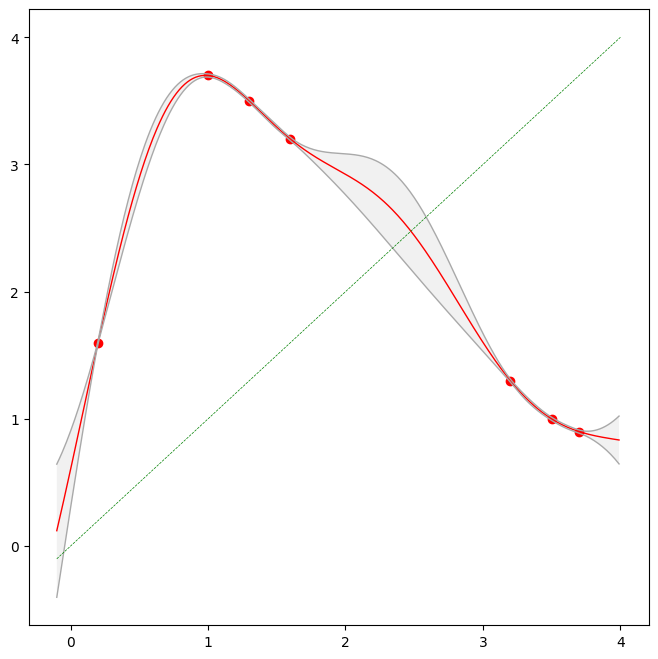

In [7]:
# Plot true map and prediction wth confidence band
fig, ax = plt.subplots(figsize=(8, 8))

# Plot sample points
plt.plot(X, Y, 'ro')

# Plot Prediction map in RED
t = np.arange(lower_bounds[0], upper_bounds[0], 0.01)
g_t = [(g([x])[0]) for x in t]
plt.plot(t, g_t, 'r', lw=1)

# Plot confidence band in GRAY
g_upper = [(g([x])[0]) + 1.96 * ((g([x])[1])) for x in t] # 1.96 * st_dev for 95% confidence
g_lower = [(g([x])[0]) - 1.96 * ((g([x])[1])) for x in t]
plt.plot(t, g_lower, 'darkgray', t, g_upper, 'darkgray', lw=1)
plt.fill_between(t, g_upper, g_lower, facecolor='lightgray', alpha=0.3)

# Plot identity
plt.plot([lower_bounds[0], upper_bounds[0]], [lower_bounds[0], upper_bounds[0]], 'g--', lw = 0.5);

# OPTIONAL: plot sample paths from the GP posterior distribution in BLUE
# n_samples=5
# samples = gp.sample_y([[z] for z in t], n_samples, random_state=42)
# for i in range(n_samples):
#   plt.plot(t,samples[:,i],'b',lw=1)


In [8]:
# Use the CMGDB software to create a multivalued map and Conley-Morse graph for homological dynamics

morse_graph, map_graph = GPD.ConleyMorseGraph(phase_subdiv, lower_bounds, upper_bounds, g, confidence_level, L=L)

Image of multi-valued map out of bounds.


In [9]:
# Gather intervals for the Morse sets to plot
morse_nodes = morse_graph.vertices()

for morse_node in morse_nodes:
    # Get Morse set for this Morse node
    morse_set = morse_graph.morse_set_boxes(morse_node)
    # Get intervals forming this Morse set
    intervals = GPD.get_intervals(morse_set)

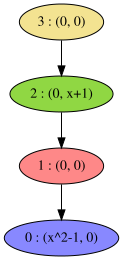

In [10]:
# Show Conley-Morse graph
num_morse_verts = len(morse_graph.vertices())
cmap = matplotlib.colors.ListedColormap(clr_list[:num_morse_verts], name='clr_list')
CMGDB.PlotMorseGraph(morse_graph, cmap=cmap)

CPU times: user 14.3 s, sys: 115 ms, total: 14.4 s
Wall time: 22.5 s


Text(0, 0.5, '$y$')

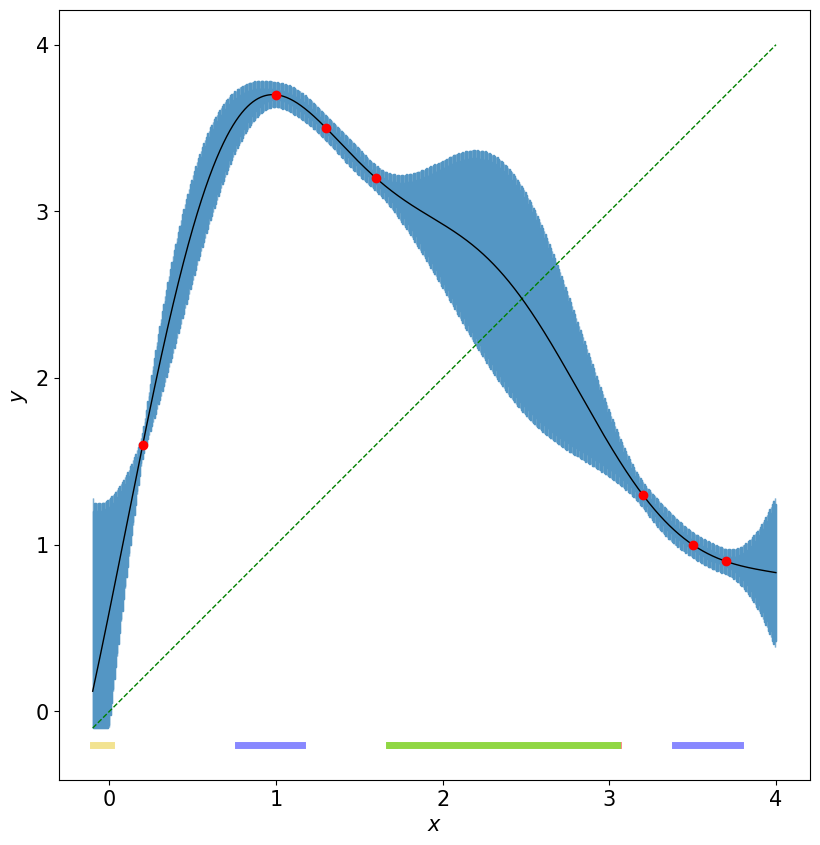

In [12]:
%%time
# Plot multivalued map and Morse sets

fig, ax = plt.subplots(figsize=(10, 10))
ax.tick_params(labelsize=15)

# y value to plot Morse sets
y_morse_sets = - 0.2

num_verts = map_graph.num_vertices()

# Create lists of boxes
mv_x = []
mv_y = []
for a in range(num_verts):
    for b in map_graph.adjacencies(a):
        mv_x.append(morse_graph.phase_space_box(a))
        mv_y.append(morse_graph.phase_space_box(b))

# Plot multivalued map as a polygonal patch of rectangles
patches = []
for box_x, box_y in zip(mv_x, mv_y):
    # Vertices of the rectangle
    v0 = (box_x[0], box_y[0])
    v1 = (box_x[1], box_y[0])
    v2 = (box_x[1], box_y[1])
    v3 = (box_x[0], box_y[1])
    # Face of rectangle
    face = (v0, v1, v2, v3)
    # Plot face
    polygon = Polygon(face, closed=True)
    patches.append(polygon)

# Create patchs collections of Polygons (rectangles)
p2 = PatchCollection(patches, color='#5496c4')

# Add collections to the axis
ax.add_collection(p2)

# Auto scale axis
ax.autoscale_view()
# Set aspect ratio
ax.set_aspect(1)

# Plot Morse sets as lines
for morse_node in morse_graph.vertices():
    # Get Morse set for this Morse node
    morse_set = morse_graph.morse_set_boxes(morse_node)
    # morse_set = [box for box in morse_sets if box[2] == morse_node]
    intervals = GPD.get_intervals(morse_set)
    clr = clr_list[morse_node]
    # Plot intervals
    for interval in intervals:
        x_min, x_max = interval
        plt.plot([x_min, x_max], [y_morse_sets, y_morse_sets], '-', color=clr, lw=5.0)

# Plot identity
plt.plot([lower_bounds[0], upper_bounds[0]], [lower_bounds[0], upper_bounds[0]], 'g--', lw=1.0)

# Plot prediction map
t = np.arange(lower_bounds[0], upper_bounds[0], 0.001)
g_t = [(g([x])[0]) for x in t]
plt.plot(t, g_t, 'black', lw=1.0);

# Plot sample
plt.plot(X, Y, 'ro', markersize=6);

ax.set_xlabel(r'$x$', fontsize=15);
ax.set_ylabel(r'$y$', fontsize=15);